| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week05** | Classification                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | October 21, 2026, 11:45 PM                                                                                                                                                                                                                                                                                          |
| **Student Name - Number & Kaggle Username**     | Edward Chisaka - 1774058, **siredwardchisaka**                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week05_ Lab implementation exercise.<br/> **_Titanic –_**.<br/> _Machine Learning from Disaster competition_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/04-assignment) |

# Import required libraries

In [1]:

# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.



# Load the competition datasets

In [40]:
train_path = Path("data/titanic/train.csv")
test_path = Path("data/titanic/test.csv")

train_df=pd.read_csv(train_path)
test_df=pd.read_csv(test_path)

display(train_df.head())

display(test_df.tail())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


# EDA - Exploratory Data Analysis

In [41]:
print("Column name:")
print(train_df.columns.tolist())

Column name:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [42]:
print("Data Types and Null Values:")
train_df.info()

Data Types and Null Values:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [43]:
print("\n First five rows:")
display(train_df.head(5))

print("\n Last five rows:")
display(train_df.tail(5))


 First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



 Last five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [44]:
print("Statistical Summary:")
# display(train_df.describe(include="all").T)
display(train_df.describe())

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [45]:
print("Missing values in training data:")
print(train_df.isnull().sum().sort_values(ascending=True))

Missing values in training data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
Age            177
Cabin          687
dtype: int64


In [46]:
print("Missing values in test data:")
print(test_df.isnull().sum().sort_values(ascending=False))

Missing values in test data:
Cabin          327
Age             86
Fare             1
PassengerId      0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Embarked         0
dtype: int64


In [47]:
print("Duplicate training rows:", train_df.duplicated().sum())

Duplicate training rows: 0


In [48]:
print("Survival count:")
print(train_df["Survived"].value_counts())

Survival count:
Survived
0    549
1    342
Name: count, dtype: int64


In [49]:
print("\nSurvival proportions:")
print(train_df["Survived"].value_counts(normalize=True).round(3))


Survival proportions:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


Text(0.5, 0, 'Passenger Class')

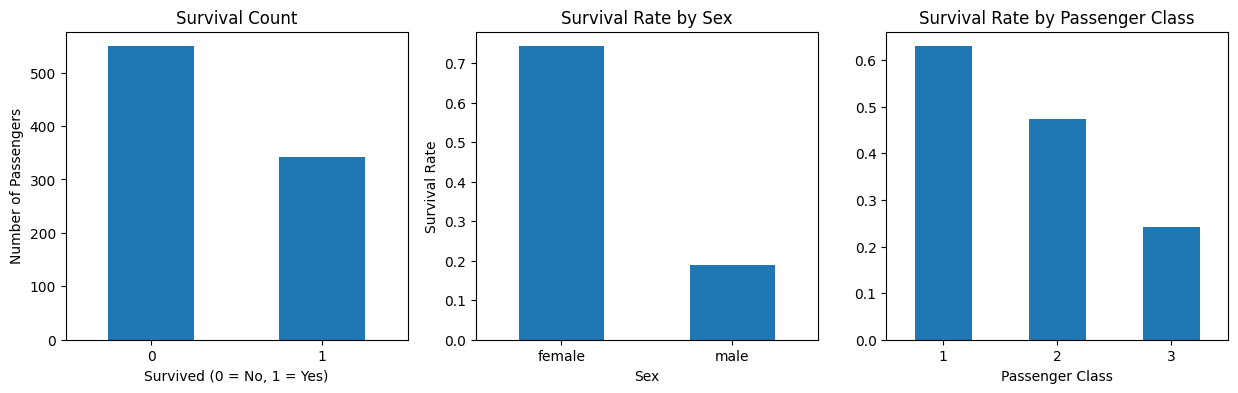

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

train_df["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Survival Count")
axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Passengers")

survival_by_sex = train_df.groupby("Sex")["Survived"].mean()
survival_by_sex.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Survival Rate by Sex")
axes[1].set_ylabel("Survival Rate")

survival_by_class = train_df.groupby("Pclass")["Survived"].mean()
survival_by_class.plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("Survival Rate by Passenger Class")
axes[2].set_xlabel("Passenger Class")

# Feature engineering

In [51]:
def create_features(data):
    data = data.copy()

    # Extract titles from passenger names.
    data["Title"] = (
        data["Name"]
        .str.extract(r",\s*([^.]*)\.", expand=False)
        .str.strip()
    )

    # Combine uncommon titles into a smaller group.
    title_counts = data["Title"].value_counts()
    common_titles = ["Mr", "Mrs", "Miss", "Master"]

    data["Title"] = data["Title"].where(
        data["Title"].isin(common_titles),
        "Rare"
    )

    data["FamilySize"] = (
        data["SibSp"] + data["Parch"] + 1
    )

    data["IsAlone"] = (
        data["FamilySize"] == 1
    ).astype(int)

    # Preserve cabin availability as a separate signal.
    data["HasCabin"] = data["Cabin"].notna().astype(int)

    data["Deck"] = (
        data["Cabin"]
        .str[0]
        .fillna("Unknown")
    )

    # Remove original columns transformed
    data = data.drop(
        columns=[
            "PassengerId",
            "Name",
            "Ticket",
            "Cabin"
        ]
    )

    return data


X = create_features(train_df.drop(columns=["Survived"]))
y = train_df["Survived"].copy()

X_test = create_features(test_df)

print("Engineered training features:")
display(X.head())

print("\nTraining features shape:", X.shape)
print("Test features shape:", X_test.shape)

Engineered training features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin,Deck
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0,Unknown
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1,C
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0,Unknown
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1,C
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0,Unknown



Training features shape: (891, 12)
Test features shape: (418, 12)


**Summary**

Title: a passenger's title, such as Mr, Mrs, Miss or Master.

FamilySize: the passenger plus siblings/spouses and parents/children.

IsAlone: whether the passenger travelled alone according to family counts.

HasCabin: whether cabin information is available.

Deck: the first letter of the cabin identifier, with missing entries represented as unknown.

# Preprocessing 

In [52]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline is ready.")

Numeric features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin']
Categorical features: ['Sex', 'Embarked', 'Title', 'Deck']
Preprocessing pipeline is ready.


# Split the training data

In [53]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target proportions:")
print(y_valid.value_counts(normalize=True).round(3))


Training rows: 712
Validation rows: 179

Training target proportions:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Validation target proportions:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


# Logistic regression model

Logistic Regression Accuracy: 0.8436

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.88       110
           1       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



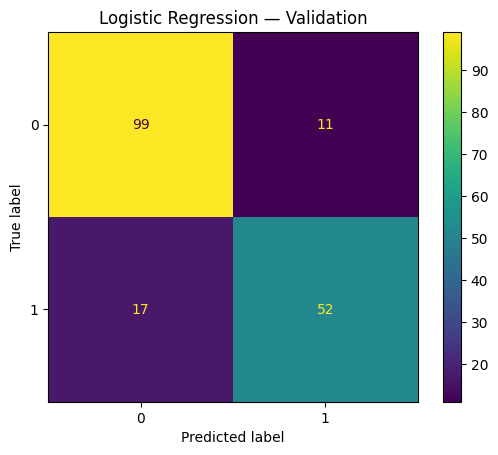

In [54]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_valid)

logistic_accuracy = accuracy_score(
    y_valid,
    logistic_predictions
)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_valid,
        logistic_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    logistic_predictions
)
plt.title("Logistic Regression — Validation")
plt.show()


**Conclusion**

The Logistic Regression model achieves an accuracy of 84.36% and a weighted F1-score of 0.84, indicating good overall classification performance. It identifies Class 0 more effectively than Class 1, as reflected by the higher recall and F1-score for Class 0 (*90%*). Although the model provides reasonably reliable predictions for both classes, the recall of *75%* for Class 1 indicates scope for improvement. Further tuning of the classification threshold, feature selection, or class-balancing techniques may help improve the detection of Class 1 observations.

# Ensemble Methods

## Random Forest

Random Forest Accuracy: 0.8045

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



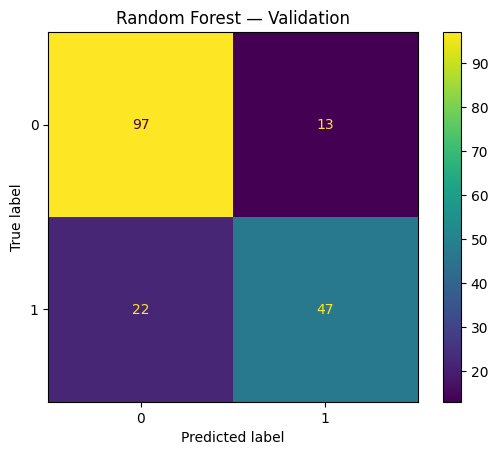

In [55]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=400,
                max_depth=8,
                min_samples_split=4,
                min_samples_leaf=2,
                class_weight=None,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_valid)

rf_accuracy = accuracy_score(y_valid, rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

print("\nClassification report:")
print(classification_report(y_valid, rf_predictions))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    rf_predictions
)
plt.title("Random Forest — Validation")
plt.show()

**Conclusion**

The Random Forest model achieves an accuracy of 80.45% and a weighted F1-score of *80%*. Although it classifies Class 0 relatively well, its recall of *0.68* for Class 1 indicates that it misses approximately one-third of the actual Class 1 cases.

Compared with Random Forest, Logistic Regression achieves higher accuracy, precision, recall, and F1-scores for both classes.

## Extra Trees Model

Extra Trees Accuracy: 0.8156

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       110
           1       0.77      0.74      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



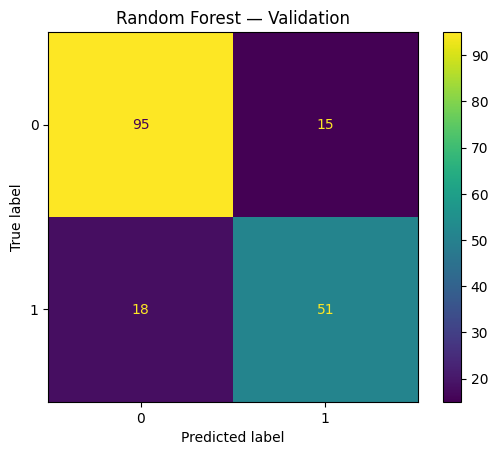

In [56]:


extra_trees_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            ExtraTreesClassifier(
                n_estimators=400,
                max_depth=8,
                min_samples_split=4,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

extra_trees_model.fit(X_train, y_train)

extra_trees_predictions = extra_trees_model.predict(X_valid)

extra_trees_accuracy = accuracy_score(
    y_valid,
    extra_trees_predictions
)

print(f"Extra Trees Accuracy: {extra_trees_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_valid,
        extra_trees_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    extra_trees_predictions
)
plt.title("Random Forest — Validation")
plt.show()

**Conclusion**

The Extra Trees Classifier achieves an accuracy of *81.56%* and a weighted F1-score of *0.81*, indicating good overall classification performance. It performs well on Class 0 and achieves a Class 1 recall of 0.74, showing a better ability to detect Class 1 cases than the Random Forest model.

Logistic Regression currently performs best across the three evaluated models.

## Ensemble using Soft Voting Classifier

Voting Ensemble Accuracy: 0.8324

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       110
           1       0.80      0.75      0.78        69

    accuracy                           0.83       179
   macro avg       0.83      0.82      0.82       179
weighted avg       0.83      0.83      0.83       179



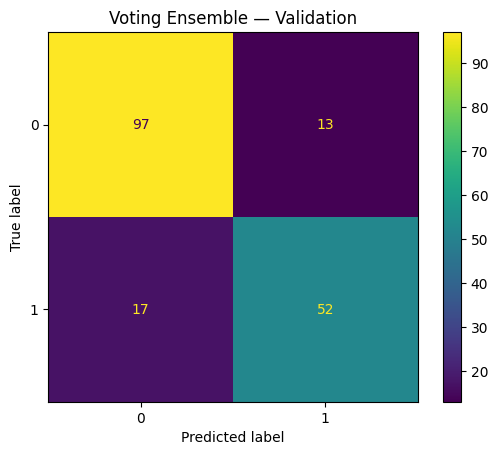

In [57]:

# Cell 11: Soft-voting ensemble

voting_model = VotingClassifier(
    estimators=[
        ("logistic", logistic_model),
        ("random_forest", random_forest_model),
        ("extra_trees", extra_trees_model)
    ],
    voting="soft",
    n_jobs=1
)

voting_model.fit(X_train, y_train)

voting_predictions = voting_model.predict(X_valid)

voting_accuracy = accuracy_score(
    y_valid,
    voting_predictions
)

print(f"Voting Ensemble Accuracy: {voting_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_valid,
        voting_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    voting_predictions
)
plt.title("Voting Ensemble — Validation")
plt.show()

**Conclusion**

The Voting Ensemble achieves an accuracy of *83.24%* and a weighted F1-score of *0.83*, demonstrating good overall classification performance. By combining Logistic Regression, Random Forest, and Extra Trees, it outperforms the individual tree-based models and achieves a Class 1 recall of *0.75*.

Logistic Regression remains the best-performing model based on the current validation results, with an accuracy of *84.36%* and a weighted F1-score of *0.84*

# Compare Validation accuracy

,Model,Validation Accuracy
0,Logistic Regression,0.843575
1,Voting Ensemble,0.832402
2,Extra Trees,0.815642
3,Random Forest,0.804469


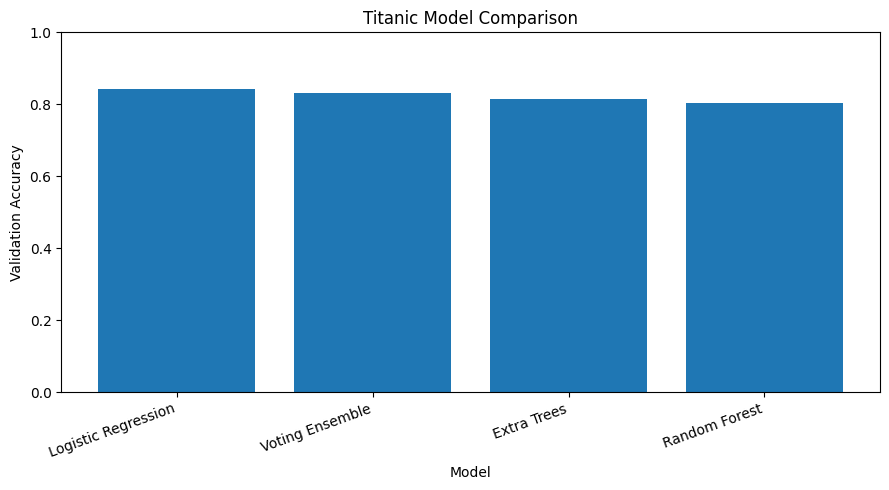

Best model on this validation split:
Logistic Regression
Validation accuracy: 0.8436


In [58]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Extra Trees",
        "Voting Ensemble"
    ],
    "Validation Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        extra_trees_accuracy,
        voting_accuracy
    ]
})

results = results.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(results)

plt.figure(figsize=(9, 5))
plt.bar(
    results["Model"],
    results["Validation Accuracy"]
)
plt.ylabel("Validation Accuracy")
plt.xlabel("Model")
plt.title("Titanic Model Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Best model on this validation split:")
print(results.iloc[0]["Model"])
print(
    "Validation accuracy:",
    round(results.iloc[0]["Validation Accuracy"], 4)
)

# Five-fold cross-validation

In [59]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Extra Trees": extra_trees_model,
    "Voting Ensemble": voting_model
}

cv_results = []

for model_name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    cv_results.append({
        "Model": model_name,
        "Mean CV Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std(),
        "Fold Scores": np.round(scores, 4).tolist()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

display(cv_df)

,Model,Mean CV Accuracy,CV Standard Deviation,Fold Scores
3,Voting Ensemble,0.831508,0.028886,"[0.8252, 0.8042, 0.8873, 0.8169, 0.8239]"
0,Logistic Regression,0.825894,0.029643,"[0.8252, 0.7902, 0.8592, 0.7958, 0.8592]"
1,Random Forest,0.820250,0.014140,"[0.8182, 0.8042, 0.8451, 0.8099, 0.8239]"
2,Extra Trees,0.817433,0.023394,"[0.8252, 0.7972, 0.8592, 0.7958, 0.8099]"


**Conclusion**

Random Forest demonstrates the greatest consistency across folds - *81.82%, 80.42%, 84.51%, 80.99%, 82.39%.*, while consequently  Voting Ensemble is the leading candidate based on mean cross-validation accuracy, at *83.15%* followed by Logistic Regression *82.59%*.

Voting Ensemble reaches the highest individual fold score, *88.73%*, but also shows some variation between folds - *82.52%, 80.42%, 88.73%, 81.69%, 82.39%*

Random Forest would be a viable model - slightly lower mean accuracy but more consistent results.

# Model Selection for Submission

In [60]:
model_registry = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Extra Trees": extra_trees_model,
    "Voting Ensemble": voting_model
}

best_model_name = results.iloc[0]["Model"]
best_model = model_registry[best_model_name]

print("Selected model:", best_model_name)
print(
    "Validation accuracy:",
    round(results.iloc[0]["Validation Accuracy"], 4)
)

Selected model: Logistic Regression
Validation accuracy: 0.8436


In [61]:
model_registry = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Extra Trees": extra_trees_model,
    "Voting Ensemble": voting_model
}

# Select the most consistent model across CV folds.
best_row = cv_df.sort_values(
    by=["CV Standard Deviation", "Mean CV Accuracy"],
    ascending=[True, False]
).iloc[0]

best_model_name = best_row["Model"]
best_model = model_registry[best_model_name]

print("Selected model:", best_model_name)
print("Mean CV accuracy:", round(best_row["Mean CV Accuracy"], 4))
print("CV standard deviation:", round(best_row["CV Standard Deviation"], 4))
print("Fold scores:", best_row["Fold Scores"])

Selected model: Random Forest
Mean CV accuracy: 0.8203
CV standard deviation: 0.0141
Fold scores: [0.8182, 0.8042, 0.8451, 0.8099, 0.8239]


**Conclusion**

Random Forest is the best choice given the consistency across folds.

Logistic Regression achieved the highest validation accuracy of *84.36%* and a mean cross-validation accuracy of *82.59%* and overall simpler model.

Logistic Tegression is used as a baseline final model while Random Forest remains a useful alternative when consistency across data splits is a priority.

## Retrain using all labelled passmengers

In [62]:
best_model.fit(X, y)

print("Final model trained on all labelled passengers.")
print("Training rows used:", len(X))
print("Features available:", X.shape[1])


Final model trained on all labelled passengers.
Training rows used: 891
Features available: 12


## Predict survival for the test dataset

In [63]:
test_predictions = best_model.predict(X_test)

test_predictions = test_predictions.astype(int)

print("Number of predictions:", len(test_predictions))
print("Predicted non-survivors:", (test_predictions == 0).sum())
print("Predicted survivors:", (test_predictions == 1).sum())

print("\nFirst 10 predictions:")
print(test_predictions[:10])


Number of predictions: 418
Predicted non-survivors: 262
Predicted survivors: 156

First 10 predictions:
[0 0 0 0 1 0 1 0 1 0]


# Create the required CSV file

In [64]:
submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": test_predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

print("Submission file created successfully.")
display(submission.head(10))


Submission file created successfully.


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


# Validate the submission

In [66]:

# Cell 18: Validate the submission file

submission_check = pd.read_csv("submission.csv")

assert submission_check.columns.tolist() == [
    "PassengerId",
    "Survived"
], "Incorrect column names or order."

assert len(submission_check) == len(test_df), (
    "Submission row count does not match the test dataset."
)

assert submission_check["PassengerId"].equals(
    test_df["PassengerId"].reset_index(drop=True)
), "Passenger IDs do not match the test dataset."

assert submission_check["Survived"].notna().all(), (
    "Some predictions are missing."
)

assert set(submission_check["Survived"].unique()).issubset({
    0, 1
}), "Survived must contain only 0 or 1."

assert not submission_check["PassengerId"].duplicated().any(), (
    "Duplicate passenger IDs detected."
)

print("All submission checks passed.")
print("Rows:", len(submission_check))
print("Columns:", submission_check.columns.tolist())
print("Output file: submission.csv")

All submission checks passed.
Rows: 418
Columns: ['PassengerId', 'Survived']
Output file: submission.csv
